In [1]:
from pathlib import Path

PROJECT_ROOT = Path(r"E:\Rasengan\Cloud-Removal")
DATA_ROOT = Path(r"D:\data")

print("Project folder exists:", PROJECT_ROOT.exists())
print("Dataset folder exists:", DATA_ROOT.exists())

if DATA_ROOT.exists():
    print("\nDataset contents:")
    for item in sorted(DATA_ROOT.iterdir()):
        print(item.name)

Project folder exists: True
Dataset folder exists: True

Dataset contents:
cloudy
non cloudy


In [2]:
from pathlib import Path

CLOUDY_DIR = DATA_ROOT / "cloudy"
CLEAR_DIR = DATA_ROOT / "non cloudy"

print("Cloudy folder exists:", CLOUDY_DIR.exists())
print("Clear folder exists:", CLEAR_DIR.exists())

print("\nCloudy folder — first 15 items:")
for item in sorted(CLOUDY_DIR.iterdir())[:15]:
    print(item.name)

print("\nNon-cloudy folder — first 15 items:")
for item in sorted(CLEAR_DIR.iterdir())[:15]:
    print(item.name)

print("\nTotal cloudy items:", len(list(CLOUDY_DIR.iterdir())))
print("Total non-cloudy items:", len(list(CLEAR_DIR.iterdir())))

Cloudy folder exists: True
Clear folder exists: True

Cloudy folder — first 15 items:
ahemadabad1
ahemadabad2
chennai1
gumla1
gumla2
gumla3
jaipur1
jaipur2
jaipur3
katiyana1
katiyana2
mandi1
nzb1
nzb2
patna1

Non-cloudy folder — first 15 items:
ahemadabad1
ahemadabad2
chennai1
gumla1
gumla2
gumla3
jaipur1
jaipur2
jaipur3
katiyana1
katiyana2
mandi1
nzb1
nzb2
patna1

Total cloudy items: 22
Total non-cloudy items: 22


In [3]:
BANDS = ["BAND2.TIF", "BAND3.TIF", "BAND4.TIF"]

cloudy_scenes = {p.name for p in CLOUDY_DIR.iterdir() if p.is_dir()}
clear_scenes = {p.name for p in CLEAR_DIR.iterdir() if p.is_dir()}

print("Matching scene names:", len(cloudy_scenes & clear_scenes))
print("Cloudy-only scenes:", sorted(cloudy_scenes - clear_scenes))
print("Clear-only scenes:", sorted(clear_scenes - cloudy_scenes))

print("\nBand-file validation:")
for scene in sorted(cloudy_scenes | clear_scenes):
    cloudy_path = CLOUDY_DIR / scene
    clear_path = CLEAR_DIR / scene

    cloudy_missing = [b for b in BANDS if not (cloudy_path / b).is_file()]
    clear_missing = [b for b in BANDS if not (clear_path / b).is_file()]

    status = "OK" if not cloudy_missing and not clear_missing else "CHECK"
    print(f"{scene}: {status}")

    if cloudy_missing:
        print("  Missing cloudy bands:", cloudy_missing)
    if clear_missing:
        print("  Missing clear bands:", clear_missing)

Matching scene names: 22
Cloudy-only scenes: []
Clear-only scenes: []

Band-file validation:
ahemadabad1: OK
ahemadabad2: OK
chennai1: OK
gumla1: OK
gumla2: OK
gumla3: OK
jaipur1: OK
jaipur2: OK
jaipur3: OK
katiyana1: OK
katiyana2: OK
mandi1: OK
nzb1: OK
nzb2: OK
patna1: OK
sambalpur1: OK
sambalpur2: OK
shilong: OK
tirupati1: OK
uttarpradesh1: OK
yavatmal1: OK
yavatmal2: OK


In [4]:
import rasterio

scene = "gumla2"

for label, folder in [
    ("Cloudy", CLOUDY_DIR),
    ("Clear", CLEAR_DIR)
]:
    print(f"\n{'=' * 15} {label}: {scene} {'=' * 15}")

    for band in BANDS:
        path = folder / scene / band

        with rasterio.open(path) as src:
            print(f"\n{band}")
            print("Shape:", (src.height, src.width))
            print("CRS:", src.crs)
            print("Resolution:", src.res)
            print("Data type:", src.dtypes[0])
            print("NoData:", src.nodata)
            print("Bounds:", src.bounds)
            print("Transform:", src.transform)


=============== Cloudy: gumla2 ===============

BAND2.TIF
Shape: (16224, 18346)
CRS: PROJCS["WGS 84 / UTM zone 45N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.25722293287,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",87],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32645"]]
Resolution: (5.0, 5.0)
Data type: uint16
NoData: None
Bounds: BoundingBox(left=164608.94308370308, bottom=2573862.5, right=256338.94308370308, top=2654982.5)
Transform: | 5.00, 0.00, 164608.94|
| 0.00,-5.00, 2654982.50|
| 0.00, 0.00, 1.00|

BAND3.TIF
Shape: (16224, 18346)
CRS: PROJCS["WGS 84 / UTM zone 45N",GEOGCS["WGS 84",DATUM["WGS_198

In [5]:
import rasterio
import pandas as pd

records = []

for scene in sorted(cloudy_scenes & clear_scenes):
    for band in BANDS:
        with rasterio.open(CLOUDY_DIR / scene / band) as cloudy, \
             rasterio.open(CLEAR_DIR / scene / band) as clear:

            same_crs = cloudy.crs == clear.crs
            same_resolution = cloudy.res == clear.res
            same_grid = (
                same_crs
                and same_resolution
                and cloudy.width == clear.width
                and cloudy.height == clear.height
                and cloudy.transform == clear.transform
            )

            records.append({
                "scene": scene,
                "band": band,
                "cloudy_shape": f"{cloudy.height}x{cloudy.width}",
                "clear_shape": f"{clear.height}x{clear.width}",
                "same_crs": same_crs,
                "same_resolution": same_resolution,
                "same_grid": same_grid,
                "cloudy_left": cloudy.bounds.left,
                "clear_left": clear.bounds.left,
                "cloudy_top": cloudy.bounds.top,
                "clear_top": clear.bounds.top
            })

alignment_df = pd.DataFrame(records)

print("Scene pairs inspected:", alignment_df["scene"].nunique())
print("Band comparisons:", len(alignment_df))
print("\nCRS mismatches:", (~alignment_df["same_crs"]).sum())
print("Resolution mismatches:", (~alignment_df["same_resolution"]).sum())
print("Identical grids:", alignment_df["same_grid"].sum())
print("Different grids:", (~alignment_df["same_grid"]).sum())

display(alignment_df[alignment_df["band"] == "BAND2.TIF"].reset_index(drop=True))

Scene pairs inspected: 22
Band comparisons: 66

CRS mismatches: 0
Resolution mismatches: 0
Identical grids: 0
Different grids: 66


,scene,band,cloudy_shape,clear_shape,same_crs,same_resolution,same_grid,cloudy_left,clear_left,cloudy_top,clear_top
0,ahemadabad1,BAND2.TIF,16258x18299,16235x18340,True,True,False,263618.943084,265953.943084,2638467.5,2638617.5
1,ahemadabad2,BAND2.TIF,16890x17777,16913x17739,True,True,False,758643.943084,759048.943084,2576237.5,2576567.5
2,chennai1,BAND2.TIF,16374x17942,16339x17976,True,True,False,308368.943084,306138.943084,1532602.5,1532662.5
3,gumla1,BAND2.TIF,16368x18274,16164x18120,True,True,False,270288.943084,270398.943084,2653627.5,2653237.5
4,gumla2,BAND2.TIF,16224x18346,16220x18358,True,True,False,164608.943084,165573.943084,2654982.5,2655092.5
5,gumla3,BAND2.TIF,16309x18192,16319x18266,True,True,False,258488.943084,257703.943084,2588122.5,2588067.5
6,jaipur1,BAND2.TIF,16484x18125,16661x18206,True,True,False,468973.943084,470038.943084,3032577.5,3033297.5
7,jaipur2,BAND2.TIF,16598x18005,16619x17948,True,True,False,508863.943084,508958.943084,3048152.5,3048272.5
8,jaipur3,BAND2.TIF,16609x17973,16638x17983,True,True,False,572673.943084,573753.943084,3033387.5,3033762.5
9,katiyana1,BAND2.TIF,16730x17900,16682x17900,True,True,False,602988.943084,604363.943084,2375657.5,2375847.5


In [6]:
import rasterio
import pandas as pd

overlap_records = []

for scene in sorted(cloudy_scenes & clear_scenes):
    cloudy_path = CLOUDY_DIR / scene / "BAND2.TIF"
    clear_path = CLEAR_DIR / scene / "BAND2.TIF"

    with rasterio.open(cloudy_path) as cloudy, \
         rasterio.open(clear_path) as clear:

        left = max(cloudy.bounds.left, clear.bounds.left)
        right = min(cloudy.bounds.right, clear.bounds.right)
        bottom = max(cloudy.bounds.bottom, clear.bounds.bottom)
        top = min(cloudy.bounds.top, clear.bounds.top)

        overlap_width = max(0, right - left)
        overlap_height = max(0, top - bottom)

        overlap_records.append({
            "scene": scene,
            "overlap_width_m": overlap_width,
            "overlap_height_m": overlap_height,
            "overlap_area_km2": overlap_width * overlap_height / 1_000_000,
            "overlap_width_pixels": round(overlap_width / cloudy.res[0]),
            "overlap_height_pixels": round(overlap_height / cloudy.res[1]),
            "has_overlap": overlap_width > 0 and overlap_height > 0
        })

overlap_df = pd.DataFrame(overlap_records)

print("Pairs with geographic overlap:",
      overlap_df["has_overlap"].sum(), "/", len(overlap_df))
display(overlap_df.round(3))

Pairs with geographic overlap: 22 / 22


,scene,overlap_width_m,overlap_height_m,overlap_area_km2,overlap_width_pixels,overlap_height_pixels,has_overlap
0,ahemadabad1,89160.0,81025.0,7224.189,17832,16205,True
1,ahemadabad2,88480.0,84235.0,7453.113,17696,16847,True
2,chennai1,87650.0,81635.0,7155.308,17530,16327,True
3,gumla1,90600.0,80820.0,7322.292,18120,16164,True
4,gumla2,90765.0,80990.0,7351.057,18153,16198,True
5,gumla3,90545.0,81490.0,7378.512,18109,16298,True
6,jaipur1,89560.0,82420.0,7381.535,17912,16484,True
7,jaipur2,89740.0,82975.0,7446.176,17948,16595,True
8,jaipur3,88785.0,82815.0,7352.730,17757,16563,True
9,katiyana1,88125.0,83220.0,7333.762,17625,16644,True


In [7]:
import rasterio
import pandas as pd

grid_records = []

for scene in sorted(cloudy_scenes & clear_scenes):
    with rasterio.open(CLOUDY_DIR / scene / "BAND2.TIF") as cloudy, \
         rasterio.open(CLEAR_DIR / scene / "BAND2.TIF") as clear:

        dx = (clear.transform.c - cloudy.transform.c) / cloudy.res[0]
        dy = (cloudy.transform.f - clear.transform.f) / cloudy.res[1]

        grid_records.append({
            "scene": scene,
            "column_offset_pixels": dx,
            "row_offset_pixels": dy,
            "column_offset_integer": abs(dx - round(dx)) < 1e-6,
            "row_offset_integer": abs(dy - round(dy)) < 1e-6
        })

grid_df = pd.DataFrame(grid_records)

print("Pairs with integer-pixel offsets:",
      (grid_df["column_offset_integer"] &
       grid_df["row_offset_integer"]).sum(), "/", len(grid_df))

display(grid_df.round(4))

Pairs with integer-pixel offsets: 22 / 22


,scene,column_offset_pixels,row_offset_pixels,column_offset_integer,row_offset_integer
0,ahemadabad1,467.0,-30.0,True,True
1,ahemadabad2,81.0,-66.0,True,True
2,chennai1,-446.0,-12.0,True,True
3,gumla1,22.0,78.0,True,True
4,gumla2,193.0,-22.0,True,True
5,gumla3,-157.0,11.0,True,True
6,jaipur1,213.0,-144.0,True,True
7,jaipur2,19.0,-24.0,True,True
8,jaipur3,216.0,-75.0,True,True
9,katiyana1,275.0,-38.0,True,True


In [8]:
import rasterio
import pandas as pd

crop_records = []

for scene in sorted(cloudy_scenes & clear_scenes):
    with rasterio.open(CLOUDY_DIR / scene / "BAND2.TIF") as cloudy, \
         rasterio.open(CLEAR_DIR / scene / "BAND2.TIF") as clear:

        col_offset = round(
            (clear.transform.c - cloudy.transform.c) / cloudy.res[0]
        )
        row_offset = round(
            (cloudy.transform.f - clear.transform.f) / cloudy.res[1]
        )

        cloudy_col_start = max(0, col_offset)
        clear_col_start = max(0, -col_offset)
        cloudy_row_start = max(0, row_offset)
        clear_row_start = max(0, -row_offset)

        width = min(
            cloudy.width - cloudy_col_start,
            clear.width - clear_col_start
        )
        height = min(
            cloudy.height - cloudy_row_start,
            clear.height - clear_row_start
        )

        crop_records.append({
            "scene": scene,
            "cloudy_row_start": cloudy_row_start,
            "cloudy_col_start": cloudy_col_start,
            "clear_row_start": clear_row_start,
            "clear_col_start": clear_col_start,
            "common_height": height,
            "common_width": width,
            "valid_crop": height > 0 and width > 0
        })

crop_df = pd.DataFrame(crop_records)

print("Scene pairs checked:", len(crop_df))
print("Pairs with valid common-grid crops:", crop_df["valid_crop"].sum())
display(crop_df)

Scene pairs checked: 22
Pairs with valid common-grid crops: 22


,scene,cloudy_row_start,cloudy_col_start,clear_row_start,clear_col_start,common_height,common_width,valid_crop
0,ahemadabad1,0,467,30,0,16205,17832,True
1,ahemadabad2,0,81,66,0,16847,17696,True
2,chennai1,0,0,12,446,16327,17530,True
3,gumla1,78,22,0,0,16164,18120,True
4,gumla2,0,193,22,0,16198,18153,True
5,gumla3,11,0,0,157,16298,18109,True
6,jaipur1,0,213,144,0,16484,17912,True
7,jaipur2,0,19,24,0,16595,17948,True
8,jaipur3,0,216,75,0,16563,17757,True
9,katiyana1,0,275,38,0,16644,17625,True


In [9]:
expected_scenes = sorted(cloudy_scenes & clear_scenes)
reported_scenes = set(crop_df["scene"])

print("Expected scene pairs:", len(expected_scenes))
print("Crop records:", len(crop_df))
print("Missing scene records:", sorted(set(expected_scenes) - reported_scenes))
print("Unexpected scene records:", sorted(reported_scenes - set(expected_scenes)))

print("\nInvalid crop dimensions:")
display(
    crop_df[
        (crop_df["common_height"] <= 0) |
        (crop_df["common_width"] <= 0)
    ]
)

print("\nSmallest common crop dimensions:")
display(
    crop_df.nsmallest(5, "common_height")[
        ["scene", "common_height", "common_width"]
    ]
)

Expected scene pairs: 22
Crop records: 22
Missing scene records: []
Unexpected scene records: []

Invalid crop dimensions:


,scene,cloudy_row_start,cloudy_col_start,clear_row_start,clear_col_start,common_height,common_width,valid_crop



Smallest common crop dimensions:


,scene,common_height,common_width
15,sambalpur1,16129,18057
12,nzb1,16150,18096
3,gumla1,16164,18120
4,gumla2,16198,18153
0,ahemadabad1,16205,17832


In [10]:
import rasterio
from rasterio.windows import Window
from rasterio.windows import transform as window_transform
from pathlib import Path

ALIGNED_DIR = PROJECT_ROOT / "data" / "aligned"
ALIGNED_DIR.mkdir(parents=True, exist_ok=True)

for _, row in crop_df.iterrows():
    scene = row["scene"]
    print(f"Processing {scene}...")

    for label, source_dir, row_key, col_key in [
        ("cloudy", CLOUDY_DIR, "cloudy_row_start", "cloudy_col_start"),
        ("clear", CLEAR_DIR, "clear_row_start", "clear_col_start"),
    ]:
        out_dir = ALIGNED_DIR / scene / label
        out_dir.mkdir(parents=True, exist_ok=True)

        for band in BANDS:
            src_path = source_dir / scene / band
            out_path = out_dir / band

            with rasterio.open(src_path) as src:
                window = Window(
                    int(row[row_key]),
                    int(row[col_key]),
                    int(row["common_width"]),
                    int(row["common_height"])
                )

                profile = src.profile.copy()
                profile.update(
                    width=int(row["common_width"]),
                    height=int(row["common_height"]),
                    transform=window_transform(window, src.transform),
                    compress="deflate"
                )

                with rasterio.open(out_path, "w", **profile) as dst:
                    for _, dst_window in dst.block_windows(1):
                        data = src.read(1, window=Window(
                            dst_window.col_off + window.col_off,
                            dst_window.row_off + window.row_off,
                            dst_window.width,
                            dst_window.height
                        ))
                        dst.write(data, 1, window=dst_window)

print("\nAligned GeoTIFF creation complete.")
print("Output folder:", ALIGNED_DIR)

Processing ahemadabad1...
Processing ahemadabad2...
Processing chennai1...
Processing gumla1...
Processing gumla2...
Processing gumla3...
Processing jaipur1...
Processing jaipur2...
Processing jaipur3...
Processing katiyana1...
Processing katiyana2...
Processing mandi1...
Processing nzb1...
Processing nzb2...
Processing patna1...
Processing sambalpur1...
Processing sambalpur2...
Processing shilong...
Processing tirupati1...
Processing uttarpradesh1...
Processing yavatmal1...
Processing yavatmal2...

Aligned GeoTIFF creation complete.
Output folder: E:\Rasengan\Cloud-Removal\data\aligned


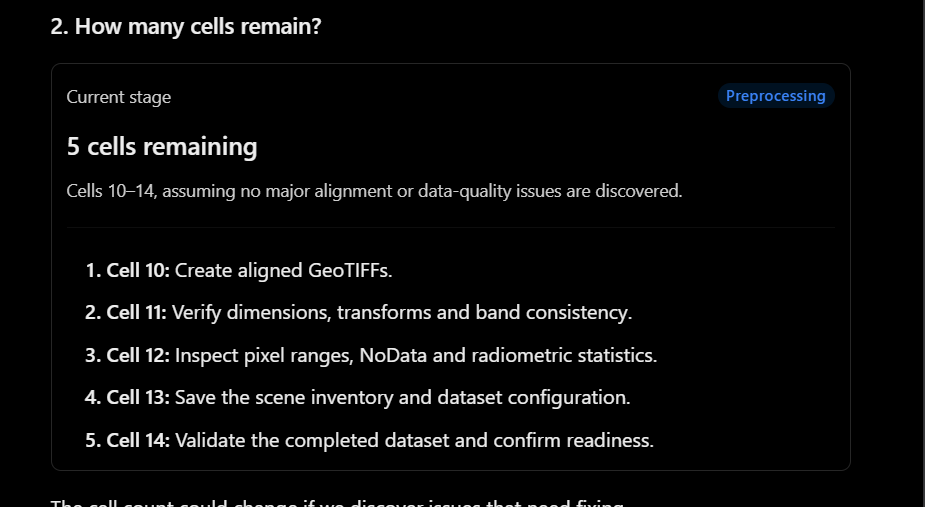

In [11]:
import rasterio
import pandas as pd

verification_records = []

for scene in sorted(cloudy_scenes & clear_scenes):
    for band in BANDS:
        cloudy_path = ALIGNED_DIR / scene / "cloudy" / band
        clear_path = ALIGNED_DIR / scene / "clear" / band

        with rasterio.open(cloudy_path) as cloudy, \
             rasterio.open(clear_path) as clear:

            verification_records.append({
                "scene": scene,
                "band": band,
                "same_shape": (
                    cloudy.height == clear.height
                    and cloudy.width == clear.width
                ),
                "same_crs": cloudy.crs == clear.crs,
                "same_transform": cloudy.transform == clear.transform,
                "same_dtype": cloudy.dtypes[0] == clear.dtypes[0],
                "cloudy_shape": f"{cloudy.height}x{cloudy.width}",
                "clear_shape": f"{clear.height}x{clear.width}"
            })

verify_df = pd.DataFrame(verification_records)

checks = [
    "same_shape",
    "same_crs",
    "same_transform",
    "same_dtype"
]

print("Band comparisons:", len(verify_df))

for check in checks:
    print(f"{check}: {verify_df[check].sum()}/{len(verify_df)} passed")

failed = verify_df[~verify_df[checks].all(axis=1)]

print("\nFailed comparisons:", len(failed))
if not failed.empty:
    display(failed)

Band comparisons: 66
same_shape: 66/66 passed
same_crs: 66/66 passed
same_transform: 0/66 passed
same_dtype: 66/66 passed

Failed comparisons: 66


,scene,band,same_shape,same_crs,same_transform,same_dtype,cloudy_shape,clear_shape
0,ahemadabad1,BAND2.TIF,True,True,False,True,16205x17832,16205x17832
1,ahemadabad1,BAND3.TIF,True,True,False,True,16205x17832,16205x17832
2,ahemadabad1,BAND4.TIF,True,True,False,True,16205x17832,16205x17832
3,ahemadabad2,BAND2.TIF,True,True,False,True,16847x17696,16847x17696
4,ahemadabad2,BAND3.TIF,True,True,False,True,16847x17696,16847x17696
...,...,...,...,...,...,...,...,...
61,yavatmal1,BAND3.TIF,True,True,False,True,16785x17700,16785x17700
62,yavatmal1,BAND4.TIF,True,True,False,True,16785x17700,16785x17700
63,yavatmal2,BAND2.TIF,True,True,False,True,16271x18103,16271x18103
64,yavatmal2,BAND3.TIF,True,True,False,True,16271x18103,16271x18103


In [12]:
import rasterio

scene = "gumla2"

for band in BANDS:
    print(f"\n{band}")

    for label in ["cloudy", "clear"]:
        path = ALIGNED_DIR / scene / label / band

        with rasterio.open(path) as src:
            print(f"{label}:")
            print("  Transform:", src.transform)
            print("  Bounds:", src.bounds)


BAND2.TIF
cloudy:
  Transform: | 5.00, 0.00, 164608.94|
| 0.00,-5.00, 2654017.50|
| 0.00, 0.00, 1.00|
  Bounds: BoundingBox(left=164608.94308370308, bottom=2573027.5, right=255373.94308370308, top=2654017.5)
clear:
  Transform: | 5.00, 0.00, 165683.94|
| 0.00,-5.00, 2655092.50|
| 0.00, 0.00, 1.00|
  Bounds: BoundingBox(left=165683.94308370308, bottom=2574102.5, right=256448.94308370308, top=2655092.5)

BAND3.TIF
cloudy:
  Transform: | 5.00, 0.00, 164608.94|
| 0.00,-5.00, 2654017.50|
| 0.00, 0.00, 1.00|
  Bounds: BoundingBox(left=164608.94308370308, bottom=2573027.5, right=255373.94308370308, top=2654017.5)
clear:
  Transform: | 5.00, 0.00, 165683.94|
| 0.00,-5.00, 2655092.50|
| 0.00, 0.00, 1.00|
  Bounds: BoundingBox(left=165683.94308370308, bottom=2574102.5, right=256448.94308370308, top=2655092.5)

BAND4.TIF
cloudy:
  Transform: | 5.00, 0.00, 164608.94|
| 0.00,-5.00, 2654017.50|
| 0.00, 0.00, 1.00|
  Bounds: BoundingBox(left=164608.94308370308, bottom=2573027.5, right=255373.9430837

In [13]:
import rasterio
import pandas as pd

corrected_records = []

for scene in sorted(cloudy_scenes & clear_scenes):
    with rasterio.open(CLOUDY_DIR / scene / "BAND2.TIF") as cloudy, \
         rasterio.open(CLEAR_DIR / scene / "BAND2.TIF") as clear:

        col_offset = round(
            (clear.transform.c - cloudy.transform.c) / cloudy.res[0]
        )
        row_offset = round(
            (cloudy.transform.f - clear.transform.f) / cloudy.res[1]
        )

        cloudy_col = max(0, col_offset)
        clear_col = max(0, -col_offset)
        cloudy_row = max(0, row_offset)
        clear_row = max(0, -row_offset)

        width = min(
            cloudy.width - cloudy_col,
            clear.width - clear_col
        )
        height = min(
            cloudy.height - cloudy_row,
            clear.height - clear_row
        )

        cloudy_transform = rasterio.windows.transform(
            rasterio.windows.Window(cloudy_col, cloudy_row, width, height),
            cloudy.transform
        )
        clear_transform = rasterio.windows.transform(
            rasterio.windows.Window(clear_col, clear_row, width, height),
            clear.transform
        )

        corrected_records.append({
            "scene": scene,
            "width": width,
            "height": height,
            "cloudy_origin": (cloudy_transform.c, cloudy_transform.f),
            "clear_origin": (clear_transform.c, clear_transform.f),
            "origins_match": (
                abs(cloudy_transform.c - clear_transform.c) < 1e-6
                and abs(cloudy_transform.f - clear_transform.f) < 1e-6
            )
        })

corrected_df = pd.DataFrame(corrected_records)

print("Scene pairs:", len(corrected_df))
print("Matching geographic origins:",
      corrected_df["origins_match"].sum(), "/", len(corrected_df))

display(corrected_df[["scene", "width", "height", "origins_match"]])

Scene pairs: 22
Matching geographic origins: 22 / 22


,scene,width,height,origins_match
0,ahemadabad1,17832,16205,True
1,ahemadabad2,17696,16847,True
2,chennai1,17530,16327,True
3,gumla1,18120,16164,True
4,gumla2,18153,16198,True
5,gumla3,18109,16298,True
6,jaipur1,17912,16484,True
7,jaipur2,17948,16595,True
8,jaipur3,17757,16563,True
9,katiyana1,17625,16644,True


In [15]:
import rasterio
from rasterio.windows import Window
from rasterio.windows import transform as window_transform

for scene in sorted(cloudy_scenes & clear_scenes):
    print(f"Processing {scene}...")

    with rasterio.open(CLOUDY_DIR / scene / BANDS[0]) as cloudy, \
         rasterio.open(CLEAR_DIR / scene / BANDS[0]) as clear:

        col_offset = round(
            (clear.transform.c - cloudy.transform.c) / cloudy.res[0]
        )
        row_offset = round(
            (cloudy.transform.f - clear.transform.f) / cloudy.res[1]
        )

        cloudy_col = max(0, col_offset)
        clear_col = max(0, -col_offset)
        cloudy_row = max(0, row_offset)
        clear_row = max(0, -row_offset)

        width = min(
            cloudy.width - cloudy_col,
            clear.width - clear_col
        )
        height = min(
            cloudy.height - cloudy_row,
            clear.height - clear_row
        )

    for label, source_dir, crop_row, crop_col in [
        ("cloudy", CLOUDY_DIR, cloudy_row, cloudy_col),
        ("clear", CLEAR_DIR, clear_row, clear_col),
    ]:
        out_dir = ALIGNED_DIR / scene / label
        out_dir.mkdir(parents=True, exist_ok=True)

        for band in BANDS:
            src_path = source_dir / scene / band
            out_path = out_dir / band
            source_window = Window(crop_col, crop_row, width, height)

            with rasterio.open(src_path) as src:
                profile = src.profile.copy()
                profile.update(
                    width=width,
                    height=height,
                    transform=window_transform(source_window, src.transform),
                    compress="deflate"
                )

                with rasterio.open(out_path, "w", **profile) as dst:
                    for _, dst_window in dst.block_windows(1):
                        src_window = Window(
                            dst_window.col_off + crop_col,
                            dst_window.row_off + crop_row,
                            dst_window.width,
                            dst_window.height
                        )
                        dst.write(
                            src.read(1, window=src_window),
                            1,
                            window=dst_window
                        )

print("\nAligned GeoTIFFs recreated.")

Processing ahemadabad1...
Processing ahemadabad2...
Processing chennai1...
Processing gumla1...
Processing gumla2...
Processing gumla3...
Processing jaipur1...
Processing jaipur2...
Processing jaipur3...
Processing katiyana1...
Processing katiyana2...
Processing mandi1...
Processing nzb1...
Processing nzb2...
Processing patna1...
Processing sambalpur1...
Processing sambalpur2...
Processing shilong...
Processing tirupati1...
Processing uttarpradesh1...
Processing yavatmal1...
Processing yavatmal2...

Aligned GeoTIFFs recreated.


In [16]:
import rasterio
import pandas as pd

verification_records = []

for scene in sorted(cloudy_scenes & clear_scenes):
    for band in BANDS:
        cloudy_path = ALIGNED_DIR / scene / "cloudy" / band
        clear_path = ALIGNED_DIR / scene / "clear" / band

        with rasterio.open(cloudy_path) as cloudy, \
             rasterio.open(clear_path) as clear:

            verification_records.append({
                "scene": scene,
                "band": band,
                "same_shape": (
                    cloudy.height == clear.height
                    and cloudy.width == clear.width
                ),
                "same_crs": cloudy.crs == clear.crs,
                "same_transform": cloudy.transform == clear.transform,
                "same_dtype": cloudy.dtypes == clear.dtypes
            })

verify_df = pd.DataFrame(verification_records)

checks = ["same_shape", "same_crs", "same_transform", "same_dtype"]

print("Band comparisons:", len(verify_df))

for check in checks:
    print(f"{check}: {verify_df[check].sum()}/{len(verify_df)} passed")

print("\nFailed comparisons:")
display(verify_df[~verify_df[checks].all(axis=1)])

Band comparisons: 66
same_shape: 66/66 passed
same_crs: 66/66 passed
same_transform: 66/66 passed
same_dtype: 66/66 passed

Failed comparisons:


,scene,band,same_shape,same_crs,same_transform,same_dtype


In [2]:
from pathlib import Path
import rasterio
import numpy as np
import pandas as pd

PROJECT_ROOT = Path(r"E:\Rasengan\Cloud-Removal")
ALIGNED_DIR = PROJECT_ROOT / "data" / "aligned"

BANDS = ["BAND2.TIF", "BAND3.TIF", "BAND4.TIF"]

scenes = sorted(
    p.name for p in ALIGNED_DIR.iterdir()
    if p.is_dir()
)

records = []

for scene in scenes:
    for image_type in ["cloudy", "clear"]:
        for band in BANDS:
            path = ALIGNED_DIR / scene / image_type / band

            if not path.is_file():
                print("Missing file:", path)
                continue

            with rasterio.open(path) as src:
                data = src.read(1, masked=True)
                values = data.compressed()

                if values.size == 0:
                    print("No valid pixels:", path)
                    continue

                records.append({
                    "scene": scene,
                    "image_type": image_type,
                    "band": band,
                    "valid_pixels": values.size,
                    "min": float(values.min()),
                    "max": float(values.max()),
                    "mean": float(values.mean()),
                    "std": float(values.std()),
                    "p01": float(np.percentile(values, 1)),
                    "p50": float(np.percentile(values, 50)),
                    "p99": float(np.percentile(values, 99))
                })

radiometric_df = pd.DataFrame(records)

print("Scene folders:", len(scenes))
print("Statistics records:", len(radiometric_df))
print("Expected records:", len(scenes) * 2 * len(BANDS))

display(
    radiometric_df.groupby(["image_type", "band"])[
        ["min", "max", "mean", "std", "p01", "p50", "p99"]
    ].agg(["min", "median", "max"]).round(3)
)

display(radiometric_df.head(12).round(3))

Scene folders: 22
Statistics records: 132
Expected records: 132


min                max                     mean  \
                      min median  max    min  median     max      min   
image_type band                                                         
clear      BAND2.TIF  0.0    0.0  0.0  191.0   483.5  1023.0   49.990   
           BAND3.TIF  0.0    0.0  0.0  234.0   615.0  1023.0   40.742   
           BAND4.TIF  0.0    0.0  0.0  329.0   616.0  1023.0  105.224   
cloudy     BAND2.TIF  0.0    0.0  0.0  631.0  1023.0  1023.0  220.509   
           BAND3.TIF  0.0    0.0  0.0  665.0  1023.0  1023.0  210.208   
           BAND4.TIF  0.0    0.0  0.0  713.0  1023.0  1023.0  274.040   

                                            std  ...           p01         \
                       median      max      min  ...      max  min median   
image_type band                                  ...                        
clear      BAND2.TIF   77.798  143.576   27.882  ...  203.315  0.0    0.0   
           BAND3.TIF   80.342  143.519   27.722  ...  210.957  0.0    0.0   
           BAND4.TIF  136.761  202.268   58.718  ...  202.911  0.0    0.0   
cloudy     BAND2.TIF  382.227  522.634  144.981  ...  339.756  0.0    0.0   
           BAND3.TIF  381.704  521.386  142.259  ...  342.397  0.0    0.0   
           BAND4.TIF  409.820  540.408  161.967  ...  335.251  0.0    0.0   

                             p50                  p99                
                      max    min median    max    min median    max  
image_type band                                                      
clear      BAND2.TIF  0.0   46.0   90.5  151.0   93.0  143.5  769.0  
           BAND3.TIF  0.0   39.0   81.5  173.0  104.0  168.0  796.0  
           BAND4.TIF  0.0   92.0  157.5  250.0  188.0  272.5  788.0  
cloudy     BAND2.TIF  0.0  192.0  410.0  613.0  466.0  850.0  942.0  
           BAND3.TIF  0.0  203.0  406.0  612.0  460.0  861.0  956.0  
           BAND4.TIF  0.0  308.0  459.0  635.0  514.0  855.5  952.0  

[6 rows x 21 columns]

,scene,image_type,band,valid_pixels,min,max,mean,std,p01,p50,p99
0,ahemadabad1,cloudy,BAND2.TIF,288967560,0.0,1023.0,417.773,258.260,0.0,462.0,866.0
1,ahemadabad1,cloudy,BAND3.TIF,288967560,0.0,1023.0,420.913,264.823,0.0,464.0,889.0
2,ahemadabad1,cloudy,BAND4.TIF,288967560,0.0,1023.0,445.413,262.017,0.0,502.0,877.0
3,ahemadabad1,clear,BAND2.TIF,288967560,0.0,748.0,61.867,32.787,0.0,74.0,113.0
4,ahemadabad1,clear,BAND3.TIF,288967560,0.0,801.0,55.813,32.813,0.0,62.0,121.0
5,ahemadabad1,clear,BAND4.TIF,288967560,0.0,858.0,128.502,72.797,0.0,149.0,253.0
6,ahemadabad2,cloudy,BAND2.TIF,298124512,0.0,1023.0,477.397,286.957,0.0,552.0,939.0
7,ahemadabad2,cloudy,BAND3.TIF,298124512,0.0,1023.0,483.556,291.547,0.0,559.0,952.0
8,ahemadabad2,cloudy,BAND4.TIF,298124512,0.0,1023.0,490.081,292.371,0.0,567.0,952.0
9,ahemadabad2,clear,BAND2.TIF,298124512,0.0,1023.0,114.627,61.582,0.0,134.0,209.0


results of radiometric
- Cloudy images: Several bands have mean values around 418–490 for the first two Ahmedabad scenes.
- Clear images: Their mean values are much lower in those scenes, around 56–178.
- Maximum values: Many cloudy bands reach 1023, which is also the maximum observed in several clear bands.
- Minimum and 1st percentile: Both are zero throughout the examples. This could indicate valid dark pixels, background pixels, or another fill-value convention; we should not assume zeros are NoData.


In [3]:
comparison = radiometric_df.pivot(
    index=["scene", "band"],
    columns="image_type",
    values=["mean", "std", "p01", "p50", "p99"]
)

comparison.columns = [
    f"{stat}_{image_type}"
    for stat, image_type in comparison.columns
]

comparison["mean_ratio_cloudy_clear"] = (
    comparison["mean_cloudy"] /
    comparison["mean_clear"].replace(0, np.nan)
)

display(
    comparison[
        [
            "mean_cloudy",
            "mean_clear",
            "p50_cloudy",
            "p50_clear",
            "p99_cloudy",
            "p99_clear",
            "mean_ratio_cloudy_clear"
        ]
    ].round(2)
)

mean_cloudy  mean_clear  p50_cloudy  p50_clear  \
scene       band                                                        
ahemadabad1 BAND2.TIF       417.77       61.87       462.0       74.0   
            BAND3.TIF       420.91       55.81       464.0       62.0   
            BAND4.TIF       445.41      128.50       502.0      149.0   
ahemadabad2 BAND2.TIF       477.40      114.63       552.0      134.0   
            BAND3.TIF       483.56      127.34       559.0      147.0   
...                            ...         ...         ...        ...   
yavatmal1   BAND3.TIF       390.69      102.24       451.0      121.0   
            BAND4.TIF       413.77      131.89       483.0      153.0   
yavatmal2   BAND2.TIF       220.51       78.77       228.0       95.0   
            BAND3.TIF       210.21       80.57       212.0       96.0   
            BAND4.TIF       274.04      130.91       308.0      160.0   

                       p99_cloudy  p99_clear  mean_ratio_cloudy_clear  
scene       band                                                       
ahemadabad1 BAND2.TIF       866.0      113.0                     6.75  
            BAND3.TIF       889.0      121.0                     7.54  
            BAND4.TIF       877.0      253.0                     3.47  
ahemadabad2 BAND2.TIF       939.0      209.0                     4.16  
            BAND3.TIF       952.0      252.0                     3.80  
...                           ...        ...                      ...  
yavatmal1   BAND3.TIF       816.0      169.0                     3.82  
            BAND4.TIF       810.0      245.0                     3.14  
yavatmal2   BAND2.TIF       583.0      134.0                     2.80  
            BAND3.TIF       599.0      146.0                     2.61  
            BAND4.TIF       616.0      230.0                     2.09  

[66 rows x 7 columns]

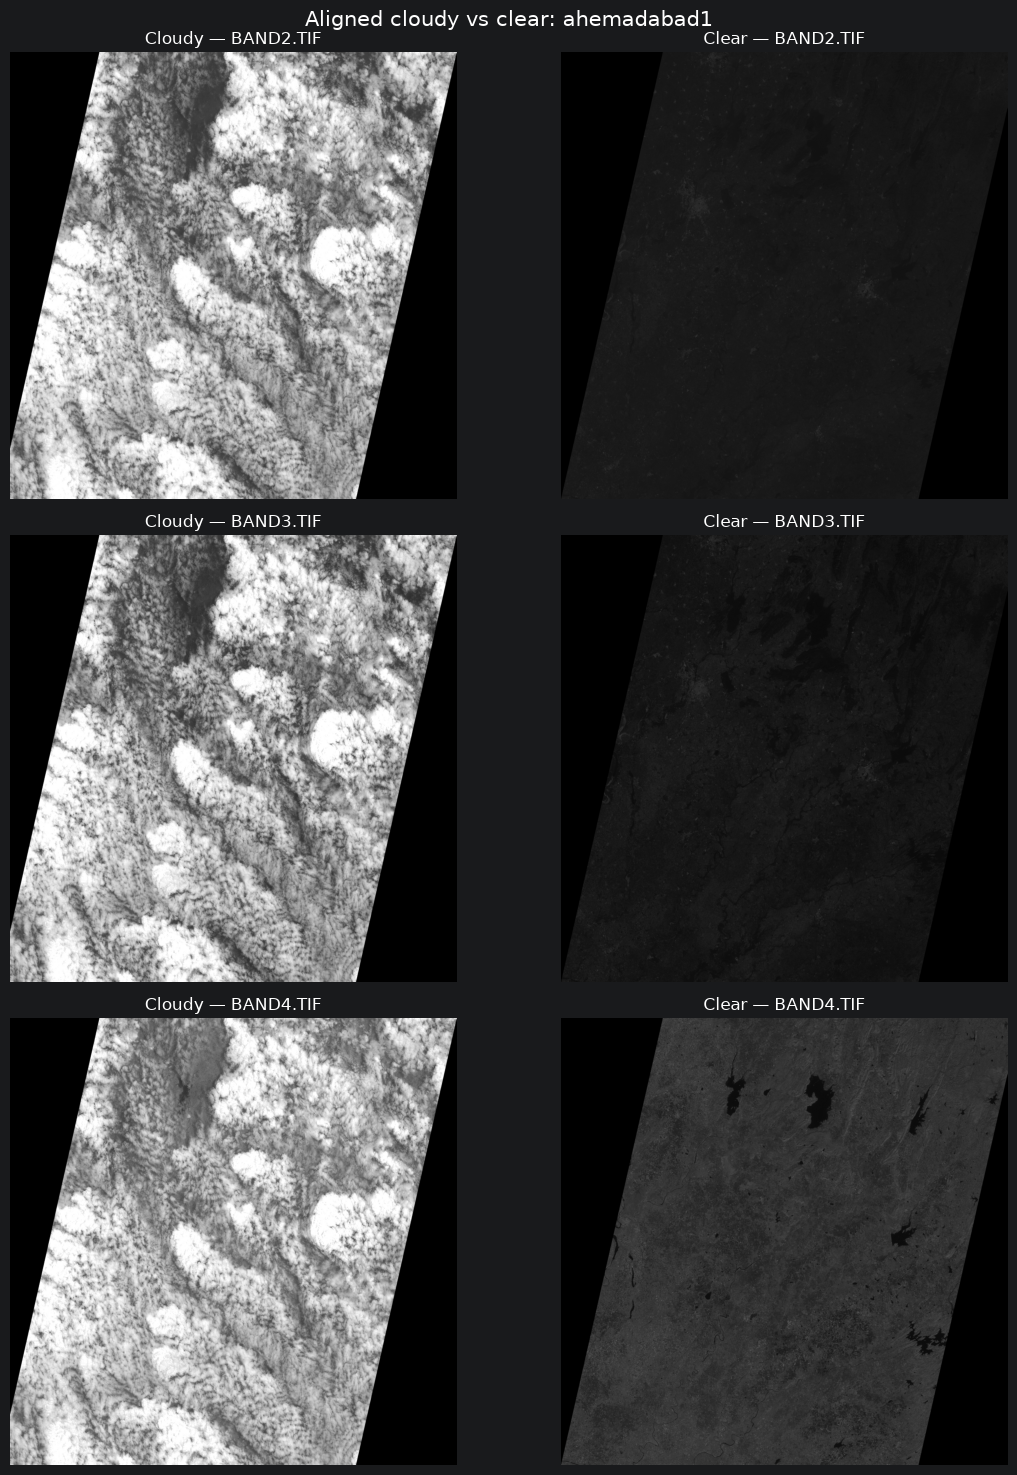

In [4]:
from pathlib import Path
import rasterio
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path(r"E:\Rasengan\Cloud-Removal")
ALIGNED_DIR = PROJECT_ROOT / "data" / "aligned"

scene = "ahemadabad1"
bands = ["BAND2.TIF", "BAND3.TIF", "BAND4.TIF"]
preview_size = 1000

fig, axes = plt.subplots(3, 2, figsize=(12, 15))

for row, band in enumerate(bands):
    paths = [
        ALIGNED_DIR / scene / "cloudy" / band,
        ALIGNED_DIR / scene / "clear" / band
    ]

    arrays = []

    for path in paths:
        with rasterio.open(path) as src:
            data = src.read(
                1,
                out_shape=(
                    min(preview_size, src.height),
                    min(preview_size, src.width)
                ),
                resampling=rasterio.enums.Resampling.average
            )
            arrays.append(data)

    combined = np.concatenate([a.ravel() for a in arrays])
    vmin, vmax = np.percentile(combined, [2, 98])

    for col, image in enumerate(arrays):
        axes[row, col].imshow(
            image, cmap="gray", vmin=vmin, vmax=vmax
        )
        axes[row, col].set_title(
            f"{'Cloudy' if col == 0 else 'Clear'} — {band}"
        )
        axes[row, col].axis("off")

plt.suptitle(f"Aligned cloudy vs clear: {scene}", fontsize=15)
plt.tight_layout()
plt.show()

In [5]:
from pathlib import Path
import rasterio

scene = "ahemadabad1"
root = Path(r"E:\Rasengan\Cloud-Removal\data\aligned")

for image_type in ["cloudy", "clear"]:
    path = root / scene / image_type / "BAND2.TIF"

    with rasterio.open(path) as src:
        print(f"\n{image_type.upper()}")
        print("Dimensions:", src.width, "x", src.height)
        print("CRS:", src.crs)
        print("Resolution:", src.res)
        print("NoData:", src.nodata)
        print("Dtype:", src.dtypes[0])
        print("Metadata:", src.tags())


CLOUDY
Dimensions: 17832 x 16205
CRS: EPSG:32643
Resolution: (5.0, 5.0)
NoData: None
Dtype: uint16
Metadata: {'AREA_OR_POINT': 'Area'}

CLEAR
Dimensions: 17832 x 16205
CRS: EPSG:32643
Resolution: (5.0, 5.0)
NoData: None
Dtype: uint16
Metadata: {'AREA_OR_POINT': 'Area'}


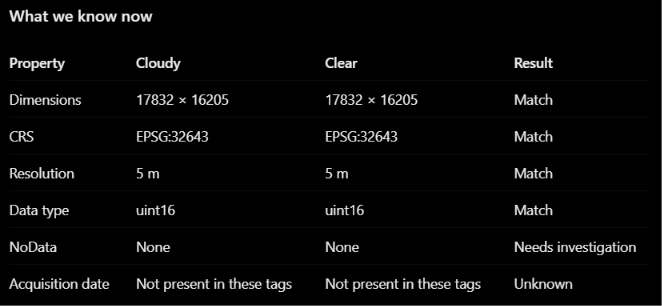

- Identified 22 cloudy/clear scene pairs, each covering the same location.
- Aligned the cloudy and clear TIFFs to matching geospatial grids.
- Verified all 66 band comparisons across the 22 pairs: dimensions, CRS, transforms, and data types match.
- Calculated radiometric statistics for all 132 rasters.
- Visually inspected one cloudy/clear pair.